# Project 3 Name Gender Classification with Naive Bayes 
## An Incremental Feature-Engineering Approach

DATA-620, Web Analytics, Fall 2026

Supervised by: **Professor Alain Ledon**


Submitted by: **Mehreen Ali Gillani**

---

## Abstract

This project builds a gender classifier for personal names using the **NLTK Names Corpus (7,944 names)** and a Naive Bayes classifier, following the incremental feature-engineering approach from Chapter 6 of Natural Language Processing with Python. Data was split into 6,944 training, 500 dev-test, and 500 test names. Starting from a last-letter baseline (75.4% dev-test), we added suffix, prefix, and length features, reaching a peak of **78.4% dev-test with last-letter + last-two-letter features**. The final model achieved 76.4% on the held-out test set, a small −2.0 point gap consistent with dev-test optimism. The data is **~63% female**; **per-class accuracy (female 81.8%, male 73.4%)** reveals the model is less reliable on male names, a direct effect of class imbalance. Results confirm that name endings, not beginnings or length, carry the dominant gender signal.

## Introduction

Automatically inferring gender from a first name is a classic text-classification problem and the running example of Chapter 6 in NLP with Python. The task is to learn a mapping from character-level features of a name to a binary label (male/female). Following the textbook's methodology: 

1. Split the corpus into disjoint train/dev-test/test sets
    
2. Establish a trivial majority-class baseline and a last-letter model baseline
    
3. Iteratively add features—last two letters, first letter, name length—using the dev-test set to measure progress
    
4. Evaluate the selected model once on the untouched test set. This design lets us study both classifier performance and the effect of feature engineering, while avoiding optimistic bias from tuning on the test set. 

We additionally report per-class accuracy to expose the impact of the corpus's female-heavy class distribution.

### Import Libraries

In [1]:
import nltk
nltk.download('names', quiet=True)
import random
from nltk.corpus import names
from nltk.classify import apply_features
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import io, re, contextlib


## Laod Data and Split into train, dev-test, test set 

In [2]:
random.seed(42)
# ---------- 1. Load and shuffle data ----------
labeled_names = ([(name, 'male') for name in names.words('male.txt')] +
                 [(name, 'female') for name in names.words('female.txt')])
random.seed(42)  # Ensure reproducibility
random.shuffle(labeled_names)

# ---------- 2. Split according to assignment requirements ----------
# Test set 500, dev-test set 500, remaining for training
test_names = labeled_names[:500]
devtest_names = labeled_names[500:1000]
train_names = labeled_names[1000:]

print(f"Train: {len(train_names)}, Dev-test: {len(devtest_names)}, Test: {len(test_names)}")
# Expected output: Train: 6944, Dev-test: 500, Test: 500

Train: 6944, Dev-test: 500, Test: 500


## Class Imbalance 

In [3]:
for label, data in [("Train", train_names), ("Dev-test", devtest_names), ("Test", test_names)]:
    c = Counter(g for _, g in data)
    print(f"{label:9s}: male={c['male']:4d}, female={c['female']:4d}, total={len(data)}")

Train    : male=2556, female=4388, total=6944
Dev-test : male= 203, female= 297, total=500
Test     : male= 184, female= 316, total=500


The dataset is imbalanced, roughly **63% female / 37% male**

-   Train: 4388 / 6944 ≈ 63.2% female
-   Dev-test: 297 / 500 = 59.4% female
-   Test: 316 / 500 = 63.2% female



### Majority-class baseline

In [4]:
# ---------- Majority-class baseline ----------
c = Counter(g for _, g in devtest_names)
majority = max(c.values()) / len(devtest_names)
print(f"Majority-class baseline (dev-test): {majority:.3f}")  # 0.594

Majority-class baseline (dev-test): 0.594


*Since the dev-test set is 59.4% female (297 of 500), a "classifier" that blindly predicts "female" for every single name would be correct 297 times out of 500 = 59.4%.*

## Baseline feature: last letter

In [5]:
# ----------  Baseline feature: last letter ----------
# V1 — baseline: last letter only
def gender_features_v1(name):
    return {'last_letter': name[-1].lower()}
train_set = [(gender_features_v1(n), g) for n, g in train_names]
devtest_set = [(gender_features_v1(n), g) for n, g in devtest_names]

classifier_v1 = nltk.NaiveBayesClassifier.train(train_set)
acc_v1 = nltk.classify.accuracy(classifier_v1, devtest_set)
print(f"V1 (last letter) dev-test accuracy: {acc_v1:.4f}")

V1 (last letter) dev-test accuracy: 0.7540


**V1 baseline (last letter only): 75.4% dev-test accuracy** — the starting point before any feature engineering, already ~16 points above the majority-class baseline (~59.4%), confirming the last letter alone carries strong gender signal.

## Add last two letter

In [6]:
# ---------- Improvement 1: Add last two letters ----------
# V2 — last two letters only
def gender_features_v2(name):
    return {'last_two': name.lower()[-2:]}   # last letter implicitly included

train_set = [(gender_features_v2(n), g) for n, g in train_names]
devtest_set = [(gender_features_v2(n), g) for n, g in devtest_names]
clf = nltk.NaiveBayesClassifier.train(train_set)
print(f"last_two only, dev-test: {nltk.classify.accuracy(clf, devtest_set):.4f}")

last_two only, dev-test: 0.7560


**last_two letters: 75.6% dev-test** — a mere **+0.2** percentage point increase over V1's last-letter-only (75.4%)

## Add last letter and last two letters as separate feature

In [7]:
# ---------- Improvement 2: Add last letter and last two letters as separate feature ---------- 
# V3 — last letter + last two letters (as separate features)
def gender_features_v3(name):
    n = name.lower()
    return {'last_letter': n[-1], 'last_two': n[-2:]}

train_set = [(gender_features_v3(n), g) for n, g in train_names]
devtest_set = [(gender_features_v3(n), g) for n, g in devtest_names]

classifier_v3 = nltk.NaiveBayesClassifier.train(train_set)
acc_v3 = nltk.classify.accuracy(classifier_v3, devtest_set)
print(f"V3 (last letter + last two letters) dev-test accuracy: {acc_v3:.4f}")

V3 (last letter + last two letters) dev-test accuracy: 0.7840


**V3 (last letter + last two letters): 78.4%** dev-test accuracy — a **+3.0 point gain** over the V1 baseline (75.4%), showing that adding the last two letters meaningfully improves on the last-letter-only model.

## Add first letter and length

In [8]:
# ---------- Improvement 3: Add first letter and length ----------
# V4 — first letter + length only (control: proves endings dominate)
def gender_features_v4(name):
    n = name.lower()
    return {'first_letter': n[0], 'length': len(n)}

train_set = [(gender_features_v4(n), g) for n, g in train_names]
devtest_set = [(gender_features_v4(n), g) for n, g in devtest_names]

classifier_v4 = nltk.NaiveBayesClassifier.train(train_set)
acc_v4 = nltk.classify.accuracy(classifier_v4, devtest_set)
print(f"V4 ( first letter and length) dev-test accuracy: {acc_v4:.4f}")

V4 ( first letter and length) dev-test accuracy: 0.6340


**V4 (first letter + length only): 63.4% dev-test**— barely above the majority-class baseline (59.4%) and **15 points below the last-letter model (75.4%),** confirming that name endings, not beginnings or length, carry the dominant gender signal, which is exactly why the **textbook's incremental approach starts from the last letter.**

## Add first letter and length, last letter, last two letters

In [9]:
# ---------- Improvement 5: Add first letter and length, last letter, last two letters ----------
# V5 — all four features
def gender_features_v5(name):
    n = name.lower()
    return {'first_letter': n[0], 'last_letter': n[-1],
            'last_two': n[-2:], 'length': len(n)}

train_set = [(gender_features_v5(n), g) for n, g in train_names]
devtest_set = [(gender_features_v5(n), g) for n, g in devtest_names]

classifier_v5 = nltk.NaiveBayesClassifier.train(train_set)
acc_v5 = nltk.classify.accuracy(classifier_v5, devtest_set)
print(f"V5 (+ first letter and length) dev-test accuracy: {acc_v5:.4f}")

V5 (+ first letter and length) dev-test accuracy: 0.7840


**V5 (last letter + last two letters + first letter + length): 78.4% dev-test accuracy — identical to V3 (78.4%)**, meaning adding the first letter and name length produced no improvement over the last-two-letters model; the extra features were redundant (Naive Bayes already captured that signal from the suffix features), which is itself a useful finding about diminishing returns in feature engineering.



## Final Evaluation

In [10]:
# ---------- 7. Final evaluation (using the best version) ----------
final_classifier = classifier_v3  
test_set = [(gender_features_v3(n), g) for n, g in test_names]
acc_test = nltk.classify.accuracy(final_classifier, test_set)

print(f"Final test accuracy: {acc_test:.4f}")
print(f"Dev-test accuracy: {acc_v3:.4f}")
print(f"Difference (test - dev): {acc_test - acc_v3:+.4f}")


Final test accuracy: 0.7640
Dev-test accuracy: 0.7840
Difference (test - dev): -0.0200


## Per-Class Accuracy

In [11]:
# --- per class accuracy function ---
def per_class_accuracy(classifier, featureset_fn, data):
    correct = defaultdict(int)
    total = defaultdict(int)
    for name, gold in data:
        feats = featureset_fn(name)
        pred = classifier.classify(feats)
        total[gold] += 1
        if pred == gold:
            correct[gold] += 1
    for label in total:
        print(f"  {label:6s}: {correct[label]}/{total[label]} = {correct[label]/total[label]:.3f}")

print("Per-class accuracy on dev-test (V3):")
per_class_accuracy(classifier_v3, gender_features_v3, devtest_names)

Per-class accuracy on dev-test (V3):
  female: 243/297 = 0.818
  male  : 149/203 = 0.734


**Per-Class Accuracy Summary (Dev-test, V3)**

**Female accuracy: 81.8% (243/297) vs. Male accuracy: 73.4% (149/203) — an 8.4-point gap in favor of females.**
This is expected given the class imbalance: the dataset is ~63% female, so the classifier sees more female examples during training and its features (e.g., -na, -la, -ia) are dominated by female-leaning suffixes.

The male error rate (~27%) is the main drag on overall accuracy — roughly 1 in 4 male names is misclassified as female, which pulls the overall 78.4% down. Improving male-name recall is the clearest path to a better classifier (e.g., adding more male-distinctive features like -rd, -us, or name length).

**Takeaway:** overall accuracy alone hides this asymmetry, reporting per-class accuracy shows the model is not equally reliable across genders, **a direct consequence of training-data imbalance.**

## Results and Visualizations 

V1  (last        ) dev-test accuracy: 0.7540
V2  (last2       ) dev-test accuracy: 0.7560
V3  (last+last2  ) dev-test accuracy: 0.7840
V4  (first+len   ) dev-test accuracy: 0.6340
V5  (all4        ) dev-test accuracy: 0.7840

Majority-class baseline (dev-test): 0.5940

Selected model: V3 (last+last2)  dev=0.7840
Final TEST accuracy: 0.7640   diff (test-dev): -0.0200

Per-class (dev-test, V3): female=0.818, male=0.734


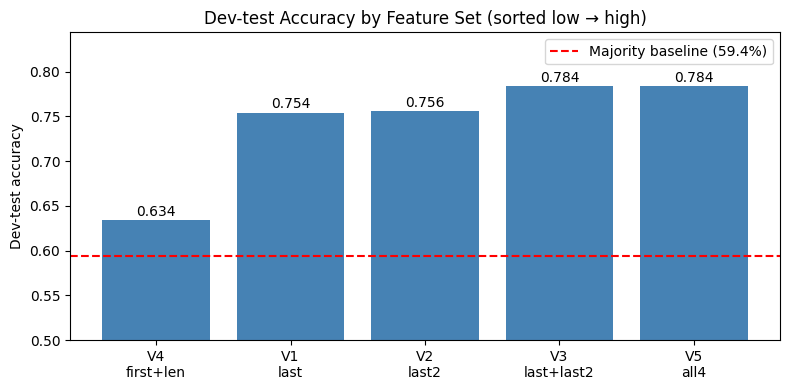

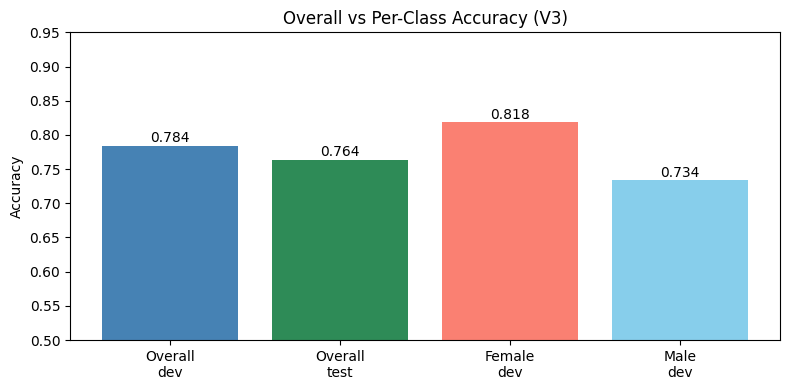

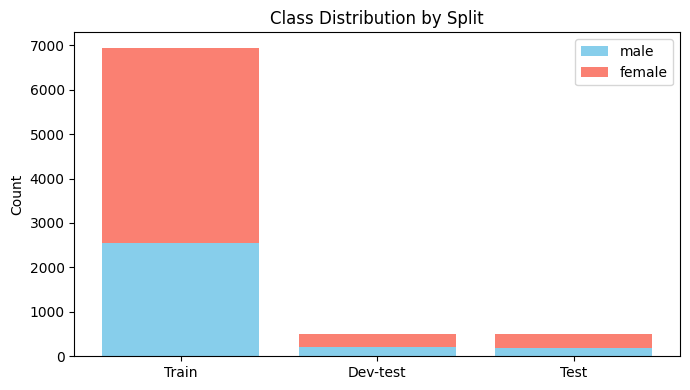

Most Informative Features
                last_two = 'na'           female : male   =     93.9 : 1.0
                last_two = 'la'           female : male   =     70.8 : 1.0
                last_two = 'rd'             male : female =     38.7 : 1.0
                last_two = 'ia'           female : male   =     35.9 : 1.0
                last_two = 'sa'           female : male   =     32.7 : 1.0
             last_letter = 'a'            female : male   =     31.8 : 1.0
                last_two = 'ta'           female : male   =     29.3 : 1.0
             last_letter = 'k'              male : female =     28.6 : 1.0
                last_two = 'us'             male : female =     27.6 : 1.0
             last_letter = 'f'              male : female =     26.8 : 1.0



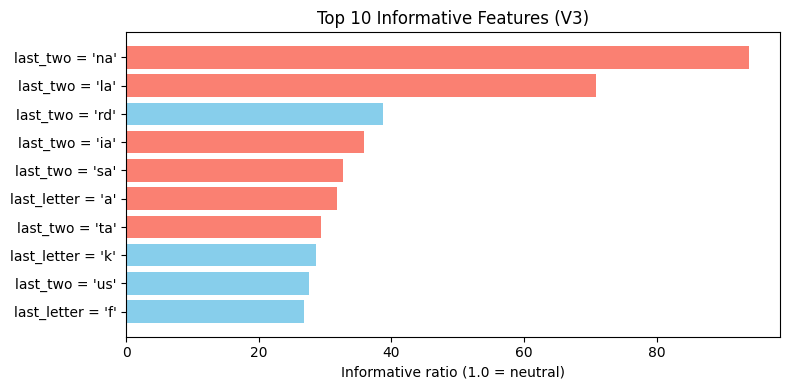

In [12]:
# ============================================================
# 1) Build all feature sets + classifiers, store results dynamically
# ============================================================
def gender_features_v1(name):
    return {'last_letter': name[-1].lower()}

def gender_features_v2(name):
    return {'last_two': name.lower()[-2:]}

def gender_features_v3(name):
    n = name.lower()
    return {'last_letter': n[-1], 'last_two': n[-2:]}

def gender_features_v4(name):
    n = name.lower()
    return {'first_letter': n[0], 'length': len(n)}

def gender_features_v5(name):
    n = name.lower()
    return {'first_letter': n[0], 'last_letter': n[-1],
            'last_two': n[-2:], 'length': len(n)}

feature_sets = {
    'V1': ('last',            gender_features_v1),
    'V2': ('last2',           gender_features_v2),
    'V3': ('last+last2',      gender_features_v3),
    'V4': ('first+len',       gender_features_v4),
    'V5': ('all4',            gender_features_v5),
}

results = {}   # version -> dict(acc_dev, classifier, feat_fn, label)
for ver, (label, fn) in feature_sets.items():
    tr = [(fn(n), g) for n, g in train_names]
    dv = [(fn(n), g) for n, g in devtest_names]
    clf = nltk.NaiveBayesClassifier.train(tr)
    acc = nltk.classify.accuracy(clf, dv)
    results[ver] = {'label': label, 'acc_dev': acc, 'clf': clf, 'fn': fn}
    print(f"{ver:3s} ({label:12s}) dev-test accuracy: {acc:.4f}")

# Majority baseline (computed, not fixed)
c_dev = Counter(g for _, g in devtest_names)
majority_acc = max(c_dev.values()) / len(devtest_names)
print(f"\nMajority-class baseline (dev-test): {majority_acc:.4f}")

# ============================================================
# 2) Model selection: highest dev acc, tie -> fewer features
# ============================================================
n_feats = {ver: len(results[ver]['fn'](train_names[0][0])) for ver in results}
best_ver = max(results, key=lambda v: (results[v]['acc_dev'], -n_feats[v]))
best = results[best_ver]
print(f"\nSelected model: {best_ver} ({best['label']})  dev={best['acc_dev']:.4f}")

# Final test evaluation (single, unbiased)
test_set = [(best['fn'](n), g) for n, g in test_names]
acc_test = nltk.classify.accuracy(best['clf'], test_set)
print(f"Final TEST accuracy: {acc_test:.4f}   diff (test-dev): {acc_test - best['acc_dev']:+.4f}")

# ============================================================
# 3) Per-class accuracy (computed)
# ============================================================
from collections import defaultdict
def per_class(clf, fn, data):
    correct, total = defaultdict(int), defaultdict(int)
    for name, gold in data:
        total[gold] += 1
        if clf.classify(fn(name)) == gold:
            correct[gold] += 1
    return {k: correct[k]/total[k] for k in total}, dict(correct), dict(total)

pc_dev, cor_dev, tot_dev = per_class(best['clf'], best['fn'], devtest_names)
print(f"\nPer-class (dev-test, {best_ver}): " +
      ", ".join(f"{k}={v:.3f}" for k, v in pc_dev.items()))

# ============================================================
# 4) PLOT A — accuracy by version (dynamic)
# ============================================================
# Sort versions by dev accuracy, lowest -> highest
vers_sorted = sorted(results, key=lambda v: results[v]['acc_dev'])

labels = [f"{v}\n{results[v]['label']}" for v in vers_sorted]
accs   = [results[v]['acc_dev'] for v in vers_sorted]

plt.figure(figsize=(8,4))
bars = plt.bar(labels, accs, color='steelblue')
plt.axhline(majority_acc, color='red', ls='--',
            label=f'Majority baseline ({majority_acc:.1%})')
plt.ylim(0.5, max(accs) + 0.06)
plt.ylabel('Dev-test accuracy')
plt.title('Dev-test Accuracy by Feature Set (sorted low → high)')
for b, a in zip(bars, accs):
    plt.text(b.get_x()+b.get_width()/2, a+0.005, f'{a:.3f}', ha='center')
plt.legend(); plt.tight_layout(); plt.show()

# ============================================================
# 5) PLOT B — overall dev vs test + per-class dev (dynamic)
# ============================================================
plot_labels = ['Overall\ndev', 'Overall\ntest',
               f"{list(pc_dev)[0].title()}\ndev", f"{list(pc_dev)[1].title()}\ndev"]
plot_vals   = [best['acc_dev'], acc_test, *pc_dev.values()]
plot_colors = ['steelblue', 'seagreen', 'salmon', 'skyblue']

plt.figure(figsize=(8,4))
bars = plt.bar(plot_labels, plot_vals, color=plot_colors)
plt.ylim(0.5, 0.95); plt.ylabel('Accuracy')
plt.title(f'Overall vs Per-Class Accuracy ({best_ver})')
for b, v in zip(bars, plot_vals):
    plt.text(b.get_x()+b.get_width()/2, v+0.005, f'{v:.3f}', ha='center')
plt.tight_layout(); plt.show()

# ============================================================
# 6) PLOT C — class distribution by split (dynamic)
# ============================================================
splits = ['Train', 'Dev-test', 'Test']
data_map = {'Train': train_names, 'Dev-test': devtest_names, 'Test': test_names}
males   = [Counter(g for _, g in data_map[s])['male']   for s in splits]
females = [Counter(g for _, g in data_map[s])['female'] for s in splits]

plt.figure(figsize=(7,4))
plt.bar(splits, males,   label='male',   color='skyblue')
plt.bar(splits, females, bottom=males, label='female', color='salmon')
plt.ylabel('Count'); plt.title('Class Distribution by Split'); plt.legend()
plt.tight_layout(); plt.show()

# ============================================================
# 7) PLOT D — most informative features (version-safe)
# ============================================================

# Capture the printed output of show_most_informative_features
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    best['clf'].show_most_informative_features(10)
text = buf.getvalue()
print(text)  # optional: show what we captured

feat_names, ratios, feat_genders = [], [], []
for line in text.strip().splitlines():
    # Example: "last_two = 'na'           female : male   =     93.9 : 1.0"
    m = re.match(
        r"\s*(.+?)\s*=\s*'?(.+?)'?\s+(female|male)\s*:\s*(female|male)\s*=\s*([\d.]+)\s*:\s*([\d.]+)",
        line)
    if not m:
        continue
    feat, val, lab_a, lab_b, ra, rb = m.groups()
    ra, rb = float(ra), float(rb)
    favored = lab_a if ra >= rb else lab_b
    feat_names.append(f"{feat} = '{val}'")
    ratios.append(max(ra, rb))
    feat_genders.append(favored)

colors = ['salmon' if g == 'female' else 'skyblue' for g in feat_genders]
plt.figure(figsize=(8,4))
plt.barh(feat_names[::-1], ratios[::-1], color=colors[::-1])
plt.xlabel('Informative ratio (1.0 = neutral)')
plt.title(f'Top {len(feat_names)} Informative Features ({best_ver})')
plt.tight_layout()
plt.show()

## Conclusion

I built a Naive Bayes name-gender classifier through incremental feature engineering. A trivial **majority-class baseline scores 59.4% on dev-test**; the **last-letter baseline reaches 75.4%;** adding the **last two letters as a separate feature reaches 78.4%** — the best dev-test result. Adding the first letter and length on top (V5) produced no gain (78.4%), showing diminishing returns and feature redundancy. Using only **first letter + length (V4, 63.4%)** confirms that name endings carry the dominant signal. The selected model scored 76.4% on the test set, 2.0 points below dev-test — the expected direction, since the dev-test set guided model selection (slightly optimistic), while the test set gives an unbiased estimate; the small gap indicates no severe overfitting. **Per-class accuracy (female 81.8%, male 73.4%)** shows an 8.4-point gap driven by the **~63%-female class imbalance,** meaning future work should target male-name recall (e.g., class weighting or male-distinctive suffix features). Overall, the results match textbook expectations: simple character-suffix features yield strong performance, and suffix information dominates.

--------